# Threshold Exploration for over-integration analyses

## Library Imports

In [1]:
import warnings
import sys 
import os

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# import scipy
# import json

import scanpy as sc
import anndata
import statsmodels.stats.multitest as mtc

# Set path
notebooks_dir = os.path.abspath(os.path.join(os.getcwd(), '..'))
atlas_extension_dir = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))
sys.path.append(atlas_extension_dir)

from mapqc.MapAnalyzer import AdataHandler, MappingScoring

## General settings

In [2]:
# Set global seed
np.random.seed(42)

# Ignore warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=UserWarning)

# Set directories
DATA_DIR = os.path.abspath(os.path.join(atlas_extension_dir, "data"))

os.makedirs(os.path.join(notebooks_dir, 'scores'), exist_ok=True)
SCORES_DIR = os.path.abspath(os.path.join(notebooks_dir, "scores"))

os.makedirs(os.path.join(notebooks_dir, 'Overintegration results'), exist_ok=True)
RESULTS_DIR = os.path.abspath(os.path.join(notebooks_dir, "Overintegration results"))

# Plot settings
sns.set(rc={"figure.figsize": (12, 7)})

## Function definitions

In [3]:
def filter_query_conditions(
    query_conditions,
    selected_conditions,
):
    return {
        dataset: [
            [condition_label] if not isinstance(condition_label, list) else condition_label, 
            [excluded_cond for excluded_cond in query_conditions[dataset] 
                if excluded_cond != condition_label and 'healthy' not in excluded_cond.lower()]
            ] 
        for condition_label, dataset in zip(selected_conditions, query_conditions.keys())
    }

In [4]:
def get_rejection_table(
    aggregated_query, 
    scorer_dict, 
    sample_condition, 
    cutoff_pval = 0.05, 
    n_ct_threshold = 0, 
    return_pvalues = False
):
    
    query_summary = pd.DataFrame(
        columns = ["Dataset", "Sample_condition", "N_rejected", "N_all", "Fraction", "Accepted disease"]
    )
    cell_types_pvals = {}
    for query_dataset in aggregated_query.keys():
        pvals = []
        for ct in aggregated_query[query_dataset].cell_label.cat.categories:

            scores_query = aggregated_query[query_dataset][
                (aggregated_query[query_dataset].dataset == query_dataset)
                & (aggregated_query[query_dataset].disease_or_healthy == sample_condition)
                & (aggregated_query[query_dataset].cell_label == ct)
            ].score

            scores_reference = aggregated_query[query_dataset][
                ~(aggregated_query[query_dataset].dataset == query_dataset) 
                & (aggregated_query[query_dataset].cell_label == ct)
            ].score

            if len(scores_query) >= 3: # at least 3 samples to consider the score
                ks_pval = scorer_dict[query_dataset].perform_one_sided_ks_test(scores_query, scores_reference)
                pvals.append((ct, ks_pval))

        if len(pvals) < 1:
            continue

        tested_cell_types = pd.DataFrame(data=pvals, columns=["cell_label", "pvalue"])

        tested_cell_types["pvals_corr"] = mtc.multipletests(
            tested_cell_types["pvalue"], 
            cutoff_pval, 
            "fdr_bh"
        )[1]
        tested_cell_types["Significant"] = tested_cell_types["pvals_corr"] < cutoff_pval
        cell_types_pvals[query_dataset] = tested_cell_types

        rejected = tested_cell_types[tested_cell_types.pvals_corr < cutoff_pval]

        summary = {
            "Dataset": query_dataset, 
            "Sample_condition": sample_condition, 
            "N_rejected": len(rejected), 
            "N_all": len(tested_cell_types), 
            "Fraction": len(rejected) / len(tested_cell_types), 
            "Accepted disease": len(rejected) > n_ct_threshold
        }

        query_summary = pd.concat(
            [query_summary, pd.DataFrame([summary])], 
            ignore_index=True
        )

    return (query_summary, cell_types_pvals) if return_pvalues else query_summary

In [5]:
def plot_score_distribution(aggregated_query, query_dataset_id, selected_conditions):   
    sns.violinplot(data=aggregated_query, x="cell_label", y="score", color="gray")
    sns.stripplot(
        data=aggregated_query[aggregated_query.dataset == query_dataset_id],
        x="cell_label",
        y="score",
        hue=aggregated_query.disease_or_healthy
    )
    
    # Legend
    legend = plt.gca().get_legend()
    legend.set_title("Disease status")
    legend.texts[0].set_text("Healthy")
    legend.texts[1].set_text(selected_conditions)

    plt.title(f"Reference vs. {query_dataset_id}", fontsize=20)
    plt.xticks(rotation=90)
    plt.show()

In [6]:
def rename_cell_type_updated(adata, updated_cell_type_id):
    condition = adata.obs.drop("cell_label", axis=1).eq("Alveolar fibroblasts").any(axis=1)
    adata.obs["cell_label"] = adata.obs["cell_label"].cat.add_categories([updated_cell_type_id])
    adata.obs.loc[condition, "cell_label"] = updated_cell_type_id

## Data loading 

Load atlas

In [7]:
adata = sc.read(f"{DATA_DIR}/HLCA_full_tranf.h5ad")
adata

AnnData object with n_obs × n_vars = 2282447 × 30
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmonized', 'ti

Subsample HLCA core

In [8]:
# subsample adata to reference
reference_adata = adata[adata.obs.query_or_reference == "reference"].copy()
reference_adata

AnnData object with n_obs × n_vars = 584944 × 30
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmonized', 'tis

Load Baseline scores

In [9]:
baseline_core = pd.read_csv(f"{SCORES_DIR}/baseline_HLCA_core.csv", index_col="barcode")
baseline_core

,score
barcode,
CGATGTAAGTTACGGG_SC10,0.054532
ATTCTACCAAGGTTCT_HD68,NaN
P1_2_TGCTGCTAGCTCCTCT,0.000000
CTGATAGTCTTAGAGC_F01367,0.000000
D344_Brus_Dis1_CATTCGCGTGCCTGCA-1-14,NaN
...,...
ACACCAACAAGACAC_GRO-03_biopsy,NaN
AGTGGGAGTTGTCTTT-1-7,0.210095
P3_4_TAAACCGGTGTCCTCT,0.191263


## Q2R mapping evaluation via MapQC

Select query datasets

In [10]:
query_ids = ['Sheppard_2020', 'Lafyatis_2019']
query_handlers = {}
query_conditions = {}
scorer = {}

Initialize AnnData handlers

In [11]:
for query_dataset in query_ids:   
    query_adata = adata[adata.obs.dataset == query_dataset].copy()

    adata_handler = AdataHandler(
        adata = anndata.concat([reference_adata, query_adata], axis = 0),
        workspace = RESULTS_DIR,
        ident = query_dataset + "/",  # folder that indentifies this workpartition
        log = True,  # create a logfile
    )
    query_handlers[query_dataset] = adata_handler

    lung_conditions = adata[adata.obs.dataset == query_dataset].obs.lung_condition.cat.categories.to_list()
    query_conditions[query_dataset] = lung_conditions

Logger directory already exists
Logger directory already exists


In [12]:
for dataset in query_conditions.keys():
    print(dataset, query_conditions[dataset])

Sheppard_2020 ['Healthy', 'IPF', 'Systemic sclerosis-associated ILD']
Lafyatis_2019 ['Systemic sclerosis-associated ILD']


Select disease conditions

In [13]:
selected_conditions = ['IPF', 'Systemic sclerosis-associated ILD']
#selected_conditions = ['Systemic sclerosis-associated ILD', 'Systemic sclerosis-associated ILD']
selected_query_conditions = filter_query_conditions(query_conditions, selected_conditions)
selected_query_conditions

{'Sheppard_2020': [['IPF'], ['Systemic sclerosis-associated ILD']],
 'Lafyatis_2019': [['Systemic sclerosis-associated ILD'], []]}

Standardize `.obs`

In [14]:
for query_dataset in query_ids:   
    query_handlers[query_dataset].standarize_columns(
        condition_name=selected_query_conditions[query_dataset][0], 
        query_dataset=query_dataset,
        cell_type_col="cell_label",
        dataset_col="dataset",
        sample_col="sample",
        condition_col="lung_condition",
        subject_col="donor_id",
        disease_exclude=selected_query_conditions[query_dataset][1],
    )

2023-07-21 14:40:32.016339	Standarizing columns...
2023-07-21 14:40:33.269367	Finished column standarizing

2023-07-21 14:40:33.269792	Standarizing columns...
2023-07-21 14:40:34.351074	Finished column standarizing



Compute query mixing scores

In [15]:
for query_dataset in query_ids: 
    # Instantiate scorer
    scorer[query_dataset] = MappingScoring(query_handlers[query_dataset])
    query_scores_path = os.path.join(
        RESULTS_DIR, 
        query_dataset, 
        f"scores_{selected_query_conditions[query_dataset][0][0]}.csv"
    )

    # Add baseline from disc
    scorer[query_dataset].add_baseline_simplified(
        baseline_path = os.path.join(SCORES_DIR, 'baseline_HLCA_core.csv'),
        cell_label_path = os.path.join(SCORES_DIR, 'cell_labels_HLCA_core.txt'),
    )

    if os.path.exists(query_scores_path):
        # Add mixing scores from disc
        scorer[query_dataset].add_scores(query_scores_path)
    else:
        # Compute mixing scores
        scorer[query_dataset].calculate_mixing_scores(
            adata = query_handlers[query_dataset].get_adata(),
            reinitialize = False,
            verbose = False,
            save = query_scores_path,
        )

Logger directory already exists
2023-07-21 14:40:34.734493	Baseline consists of following cell types:

2023-07-21 14:40:34.735222	AT2


2023-07-21 14:40:34.735238	Alveolar macrophages


2023-07-21 14:40:34.735248	Dendritic cells


2023-07-21 14:40:34.735256	EC arterial


2023-07-21 14:40:34.735264	EC venous


2023-07-21 14:40:34.735272	Fibroblast lineage


2023-07-21 14:40:34.735280	Goblet


2023-07-21 14:40:34.735287	Interstitial macrophages


2023-07-21 14:40:34.735295	Mast cells


2023-07-21 14:40:34.735302	Monocytes


2023-07-21 14:40:34.735309	Multiciliated (non-nasal)


2023-07-21 14:40:34.735317	NK cells


2023-07-21 14:40:34.735324	Suprabasal


2023-07-21 14:40:34.735331	T cell lineage


2023-07-21 14:40:34.735338	Transitional Club-AT2


Logger directory already exists
2023-07-21 14:40:35.504581	Baseline consists of following cell types:

2023-07-21 14:40:35.504834	AT2


2023-07-21 14:40:35.504855	Alveolar macrophages


2023-07-21 14:40:35.504867	Dendritic cells


2023-07-21 14

Add log-linear model fit from reference samples

In [16]:
for query_dataset in query_ids: 
    # Correct raw scores for sample size

    scorer[query_dataset].calculate_transformation(
        save = False
    ) 

#### Augment resolution fibro

In [17]:
# Augment resolution to Fibroblasts -> Alveolar fibroblasts
for query_dataset in query_ids: 
    rename_cell_type_updated(scorer[query_dataset].get_adata(), "Alveolar fibroblasts")

#### Transform query scores

In [18]:
aggregated_query = {}

In [19]:
for query_dataset in query_ids: 
    aggregated_query[query_dataset] = scorer[query_dataset].group_adata()
    aggregated_query[query_dataset] = scorer[query_dataset].apply_transformation(
        aggregated_query[query_dataset],
        cell_subtypes=["Fibroblast lineage", "Alveolar fibroblasts"] 
    )

2023-07-21 14:40:40.061456	Correcting for sample size...
2023-07-21 14:40:40.185120	Correcting for sample size...


Evaluate query dataset acceptance

In [20]:
rejection_table = {}
pvalues_table = {}

In [21]:
for sample_condition in ["healthy", "disease"]:
    rejection_table[sample_condition], pvalues_table[sample_condition] = get_rejection_table(
        aggregated_query, 
        scorer, 
        sample_condition=sample_condition,
        return_pvalues=True
    )

In [22]:
rejection_table

{'healthy':          Dataset Sample_condition N_rejected N_all  Fraction Accepted disease
 0  Sheppard_2020          healthy          0    11       0.0            False,
 'disease':          Dataset Sample_condition N_rejected N_all  Fraction Accepted disease
 0  Sheppard_2020          disease          0     5       0.0            False
 1  Lafyatis_2019          disease          0    16       0.0            False}

In [23]:
pvalues_table

{'healthy': {'Sheppard_2020':                   cell_label    pvalue  pvals_corr  Significant
  0                        AT2  0.970875    0.970875        False
  1       Alveolar macrophages  0.894615    0.970875        False
  2            Dendritic cells  0.607048    0.970875        False
  3                EC arterial  0.956878    0.970875        False
  4                  EC venous  0.893616    0.970875        False
  5         Fibroblast lineage  0.676797    0.970875        False
  6   Interstitial macrophages  0.872849    0.970875        False
  7                 Mast cells  0.017343    0.190776        False
  8                  Monocytes  0.863274    0.970875        False
  9      Transitional Club-AT2  0.830034    0.970875        False
  10      Alveolar fibroblasts  0.760489    0.970875        False},
 'disease': {'Sheppard_2020':                   cell_label    pvalue  pvals_corr  Significant
  0                        AT2  0.201318    0.291503        False
  1       Alveolar

Plot mixing scores

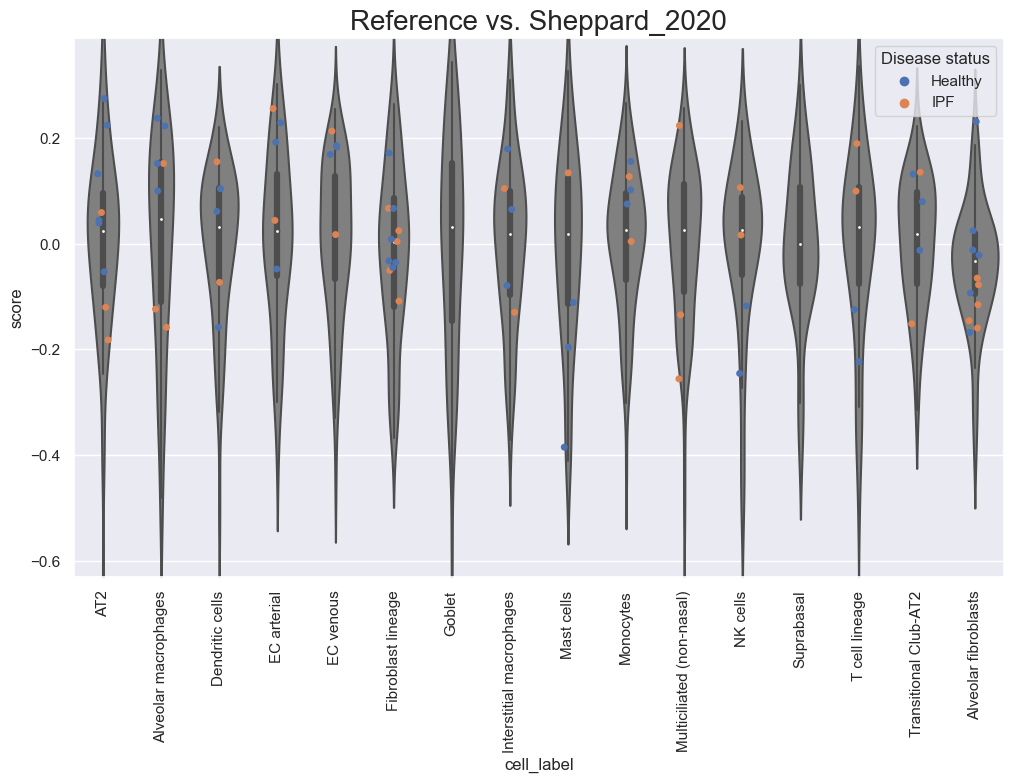

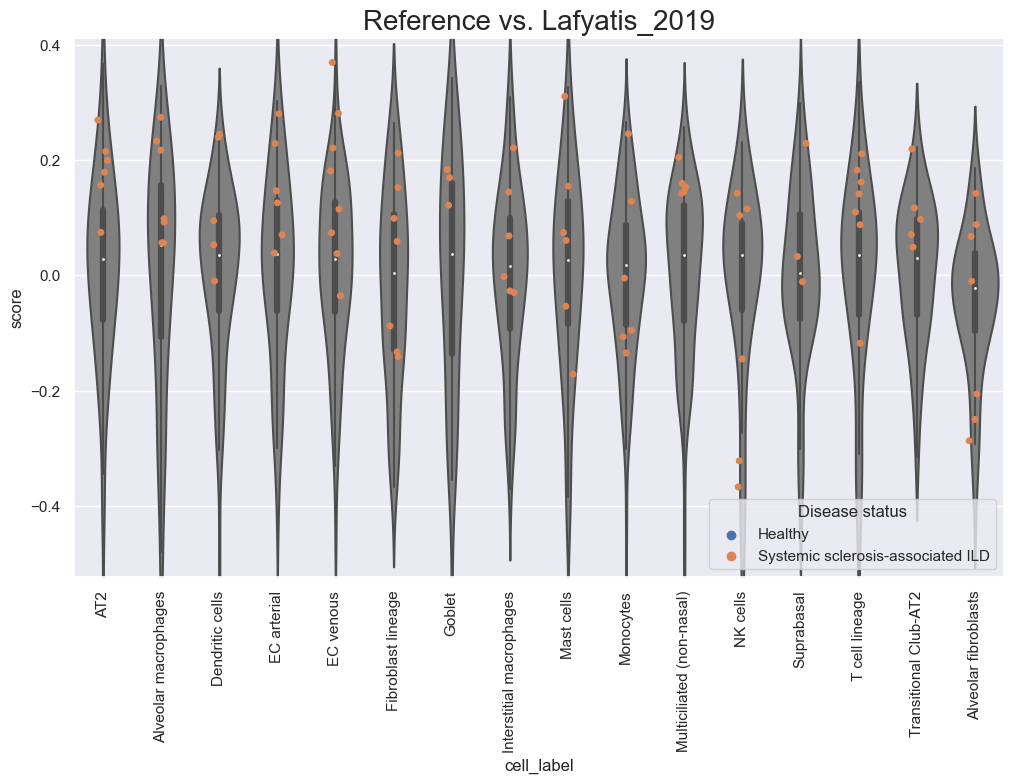

In [24]:
for query_dataset in query_ids:     
    plot_score_distribution(
        aggregated_query[query_dataset], 
        query_dataset, 
        selected_query_conditions[query_dataset][0][0]
    )